# Forecasting District-Level Paddy Yield in Sri Lanka at Sowing Time
### Applied Machine Learning – Final Assignment

**Problem (local, Sri Lankan context).** Rice is Sri Lanka's staple food and paddy is grown in two seasons:
**Maha** (north-east monsoon, roughly Oct–Mar) and **Yala** (south-west monsoon, roughly Apr–Sep).
The Department of Agriculture, the Paddy Marketing Board and district officers have to plan fertilizer
distribution, storage, purchasing and imports *before* the harvest is known.

**Goal.** At the time a season is sown, predict the **average paddy yield (kg/ha) of each district** for that season,
using only information that is already available at sowing time:
how much land was sown, under which irrigation type, and the district's yield history.
This is a **supervised regression** problem on tabular data.

**Dataset.** District-wise paddy statistics (1979–2023, Maha & Yala) published by the
Department of Census and Statistics (DCS), Sri Lanka: sown and harvested extent by irrigation type
(major irrigation, minor irrigation, rain-fed), average yields and production.

**Plan of the notebook**
1. Data audit & cleaning  2. Exploratory analysis  3. Leakage-free feature engineering
4. Time-based train/test split + one held-out sample  5. Existing approaches (baselines)
6. Ensemble models with self-designed hyperparameters (RF, XGBoost, LightGBM, CatBoost) + Stacking
7. Comparison, strengths & limitations  8. Explainability with SHAP and LIME
9. Inference on a single unseen sample from the pickled model  10. Conclusions

In [1]:
import sys, time, json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor  # used through the CatBoostSK wrapper
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import (load_and_clean, add_features, modelling_table, AGGREGATE_REGIONS,
                      FEATURES, NUM_FEATURES, CAT_FEATURES, TARGET)
from cat_wrapper import CatBoostSK

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close("all")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data audit
First look at the raw file **before** cleaning, to understand what problems need fixing.

In [2]:
raw = pd.read_csv(ROOT / "data" / "Agriculture_Statistics_Paddy.csv")
print("Raw shape:", raw.shape)
print(raw.dtypes.value_counts())
raw.head()

Raw shape: (2612, 16)
str      15
int64     1
Name: count, dtype: int64


,Year,Season,District,Major Sown (Ha),Minor Sown (Ha),Rainfed Sown (Ha),Total Extent (Ha),Major Harvest (Ha),Minor Harvest (Ha),Rainfed Harvest (Ha),Net Harvest (Ha),Major Avg Yield (MT/Ha),Minor Avg Yield (MT/Ha),Rainfed Avg Yield (MT/Ha),Average Yield (MT/Ha),Production (MT)
0,1979,MAHA,Colombo,0,158.236,"7,111.70","7,269.93",0,148.928,"6,909.75","6,000.00",0,"1,454.27","2,050.42","2,038.05","12,229.82"
1,1979,MAHA,Gampaha,"1,327.80","1,517.20","13,851.88","16,696.89","1,299.07","1,497.37","13,537.84","13,883.85","2,738.88","2,263.41","2,473.30","2,476.39","34,372.89"
2,1979,MAHA,Kalutara,0,"1,169.97","17,727.64","18,897.61",0,"1,166.33","17,198.30","16,941.32",0,"1,614.14","1,713.67","1,706.97","28,925.82"
3,1979,MAHA,Kandy,"4,295.43","10,396.20","7,676.24","22,367.87","4,276.41","10,265.48","7,599.35","17,509.11","2,835.32","3,308.22","3,264.90","3,201.47","56,056.82"
4,1979,MAHA,Matale,"3,672.60","7,135.17","3,006.88","13,814.65","3,530.15","6,894.78","2,869.69","11,955.48","3,618.15","3,150.41","3,000.86","3,245.30","38,797.33"


In [3]:
audit = {
    "numeric columns stored as text (thousand separators)": int((raw.dtypes == object).sum() + (raw.dtypes == "str").sum()) - 2,
    "'-' placeholders in Production": int((raw["Production (MT)"].astype(str).str.strip() == "-").sum()),
    "fully duplicated rows": int(raw.duplicated().sum()),
    "rows for overlapping aggregate regions": int(raw["District"].isin(AGGREGATE_REGIONS).sum()),
    "rows with zero sown extent": int((raw["Total Extent (Ha)"].astype(str).str.strip() == "0").sum()),
}
pd.Series(audit, name="count").to_frame()

,count
numeric columns stored as text (thousand separators),13
'-' placeholders in Production,175
fully duplicated rows,100
rows for overlapping aggregate regions,268
rows with zero sown extent,174


**Findings and decisions**
* All measurements are stored as text with thousand separators (`"7,111.70"`) and `-` for missing → convert to numbers, `-` → NaN.
* **100 exact duplicate rows** (years 2010–2012 were entered twice) → drop, otherwise those years get double weight and could leak between folds.
* `Udawalawe`, `Mahaweli'h'`, `Highland`, `North & East` are **irrigation-system / regional aggregates**, not districts.
  They overlap with real districts (e.g. Mahaweli areas are inside Polonnaruwa/Anuradhapura), so they are removed and the 25 administrative districts are kept.
* Seasons with **zero sown extent** (mostly Jaffna, Kilinochchi and other Northern districts during the civil-war years) have no yield to predict → excluded from modelling, but kept as "gaps" in the history.
* **Unit issue:** the column says "MT/Ha" but values are 1,150–6,600. Sri Lankan paddy yields are about 3–5 tonnes/ha, so the values are actually **kg/ha**. The target is renamed `yield_kg_ha`.

Domain knowledge was needed for the last three points. A model trained blindly on the raw Kaggle-style table would double count, mix regions with districts, and report yields 1000× too high.

In [4]:
clean = load_and_clean(ROOT / "data" / "Agriculture_Statistics_Paddy.csv")
print("After cleaning:", clean.shape, "| districts:", clean["District"].nunique(), "| years:", clean["Year"].min(), "-", clean["Year"].max())
print("Missing values per column (after converting '-' to NaN):")
print(clean.isna().sum()[lambda s: s > 0])

After cleaning: (2250, 17) | districts: 25 | years: 1979 - 2023
Missing values per column (after converting '-' to NaN):
Production (MT)    80
dtype: int64


## 2. Exploratory data analysis

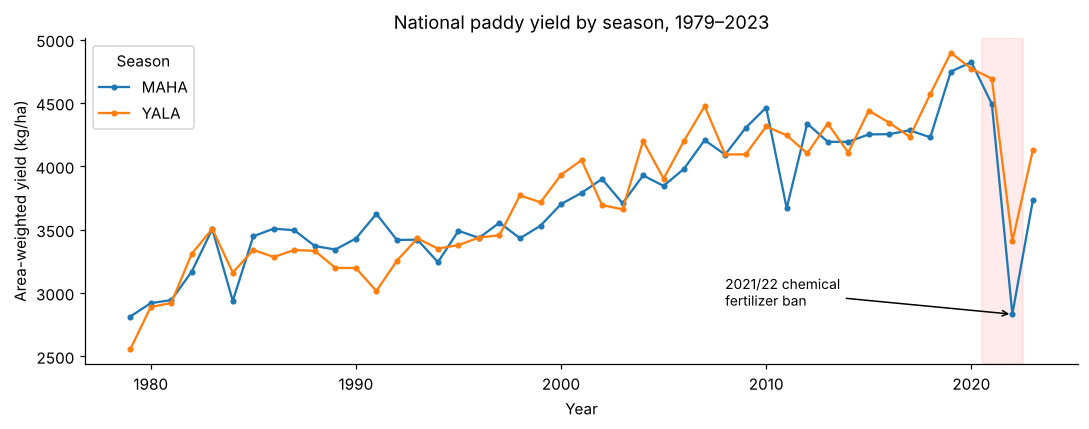

In [5]:
cult = clean[(clean["Total Extent (Ha)"] > 0) & (clean[TARGET] > 0)]
nat = cult.groupby(["Year", "Season"]).apply(
    lambda g: np.average(g[TARGET], weights=g["Net Harvest (Ha)"].fillna(g["Total Extent (Ha)"]))).unstack()
fig, ax = plt.subplots(figsize=(10, 4))
nat.plot(ax=ax, marker="o", ms=3)
ax.axvspan(2020.5, 2022.5, color="red", alpha=0.08)
ax.annotate("2021/22 chemical\nfertilizer ban", xy=(2022, nat.loc[2022].min()), xytext=(2008, 2900),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("Area-weighted yield (kg/ha)"); ax.set_title("National paddy yield by season, 1979–2023")
savefig("01_national_trend")

* Yields roughly **doubled** from ~2,600 kg/ha (1980) to ~4,500 kg/ha (2019–2021): a strong long-term trend (improved varieties, irrigation, fertilizer subsidy). `Year` is therefore a useful feature.
* **Maha and Yala behave differently**; Yala is more variable because it depends on stored tank water.
* A sharp collapse in **2022 (Maha 2021/22 and Yala 2022)**: the government's sudden ban on chemical fertilizer in 2021. This is a *structural shock* that no historical pattern can predict — important when we judge the models on 2016–2023.

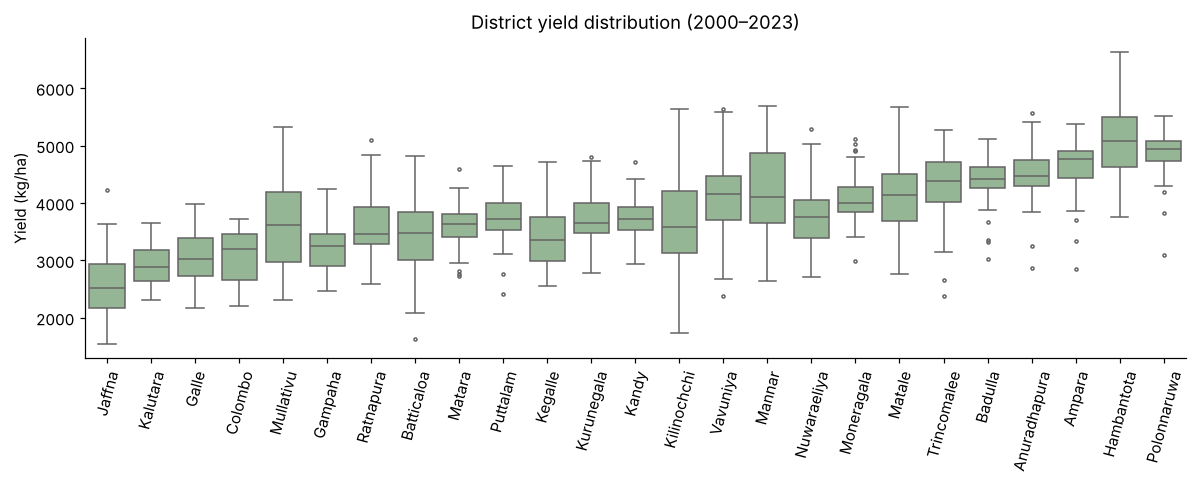

In [6]:
order = cult.groupby("District")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=cult[cult.Year >= 2000], x="District", y=TARGET, order=order, ax=ax, color="#8fbc8f", fliersize=2)
ax.tick_params(axis="x", rotation=75); ax.set_ylabel("Yield (kg/ha)"); ax.set_xlabel("")
ax.set_title("District yield distribution (2000–2023)")
savefig("02_district_box")

The dry-zone districts with large **major irrigation** schemes (Polonnaruwa, Ampara, Hambantota, Anuradhapura) have the highest yields;
wet-zone, mostly **rain-fed** districts (Colombo, Kalutara, Galle, Kegalle, Ratnapura) have the lowest. District identity carries a lot of information.

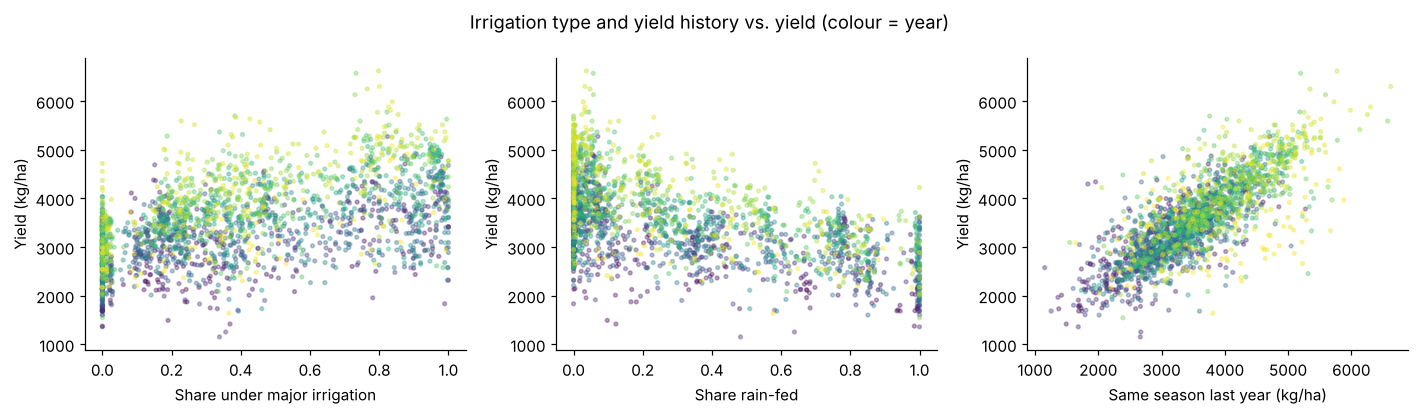

In [7]:
feat_all = add_features(clean)
model_df = modelling_table(feat_all)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, lab in zip(axes, ["share_major", "share_rainfed", "yield_same_season_ly"],
                        ["Share under major irrigation", "Share rain-fed", "Same season last year (kg/ha)"]):
    ax.scatter(model_df[col], model_df[TARGET], s=6, alpha=0.35, c=model_df["Year"], cmap="viridis")
    ax.set_xlabel(lab); ax.set_ylabel("Yield (kg/ha)")
fig.suptitle("Irrigation type and yield history vs. yield (colour = year)")
savefig("03_scatter")

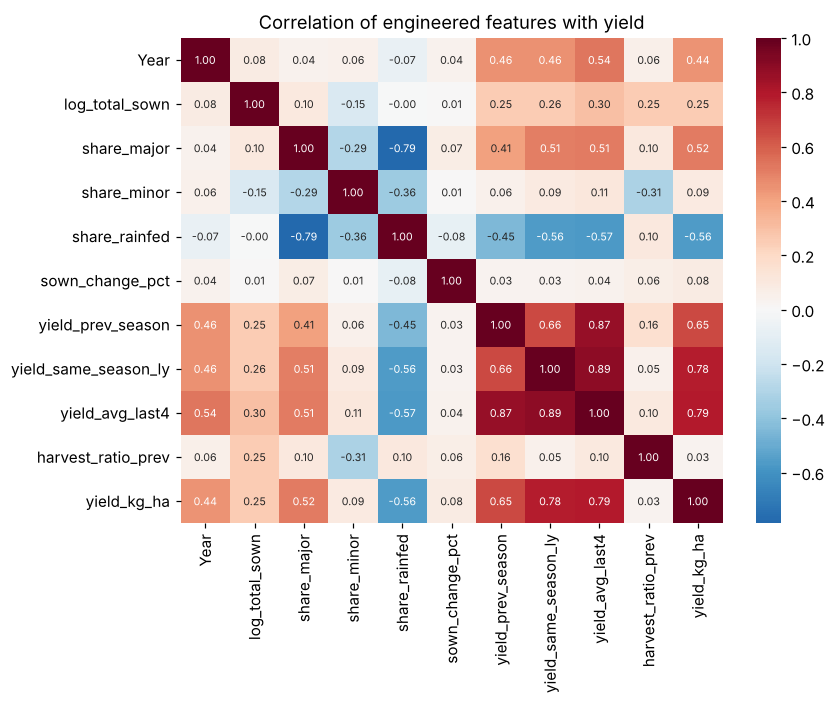

In [8]:
corr = model_df[NUM_FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation of engineered features with yield")
savefig("04_corr")

* Lagged yields correlate strongly with the target (0.65–0.79) – yields are persistent.
* `share_major` (+0.52) and `share_rainfed` (−0.56) confirm the irrigation story. They are strongly negatively correlated with each other (they sum to 1 with `share_minor`) — tree models handle this collinearity well, but it makes linear coefficients unstable.
* `harvest_ratio_prev` is close to zero linearly, but it can matter non-linearly (a previous drought/flood season).

## 3. Leakage-free feature engineering
| Feature | Meaning | Why it is allowed |
|---|---|---|
| `District`, `Season`, `Year` | where / when | known in advance |
| `log_total_sown` | log of total sown hectares | sowing is complete before the forecast |
| `share_major / minor / rainfed` | irrigation mix of the sown area | known at sowing |
| `sown_change_pct` | sown area vs. same season last year | farmers sow less when water is short – an early drought signal |
| `yield_prev_season`, `yield_same_season_ly`, `yield_avg_last4` | yield history | previous seasons are already harvested |
| `harvest_ratio_prev` | harvested ÷ sown area last season | crop loss (flood / drought) last season |

**Excluded on purpose (data leakage):** harvested extents, per-irrigation yields and production of the *current* season.
`Production = Net Harvest × Yield` exactly (checked below), so including them would let the model "read" the answer and produce a perfect but useless score.

Lags are joined on a chronological season index (`t = 2·Year + [Yala]`), not with `shift()`, so a missing season (e.g. war years in Jaffna) becomes a **missing value** instead of silently using an older season.

In [9]:
chk = clean.dropna(subset=["Production (MT)"]).query("`Net Harvest (Ha)` > 0")
ratio = chk["Production (MT)"] / (chk["Net Harvest (Ha)"] * chk[TARGET] / 1000)
print(f"Production / (Net harvest x yield/1000): median = {ratio.median():.4f}  -> confirms kg/ha and the leakage risk")
print("Modelling table:", model_df.shape)
model_df[FEATURES + [TARGET]].isna().mean().mul(100).round(1).rename("% missing").to_frame().T

Production / (Net harvest x yield/1000): median = 1.0000  -> confirms kg/ha and the leakage risk
Modelling table: (2174, 27)


,District,Season,Year,log_total_sown,share_major,share_minor,share_rainfed,sown_change_pct,yield_prev_season,yield_same_season_ly,yield_avg_last4,harvest_ratio_prev,yield_kg_ha
% missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.1,3.6,3.1,1.1,3.6,0.0


## 4. Time-based split and one held-out sample
Random splitting would let the model train on 2020 and be tested on 2019 – unrealistic for a forecast.
We use a **chronological split**:
* **Train:** 1979–2015 (≈ 37 years)  * **Test:** 2016–2023 (8 years, includes the 2022 fertilizer shock)
* **Held-out inference sample:** *Polonnaruwa, Yala 2023* is removed from everything and used only at the end to demonstrate inference with the saved pickle model.

In [10]:
HOLDOUT = (model_df["District"] == "Polonnaruwa") & (model_df["Year"] == 2023) & (model_df["Season"] == "YALA")
holdout = model_df[HOLDOUT].copy()
data = model_df[~HOLDOUT]
train = data[data["Year"] <= 2015].sort_values("t")
test = data[data["Year"] > 2015].sort_values("t")
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"train {X_train.shape}, test {X_test.shape}, holdout {holdout.shape}")
tscv = TimeSeriesSplit(n_splits=4)   # forward-chaining CV inside the training period, used for all tuning

train (1782, 12), test (391, 12), holdout (1, 27)


## 5. Preprocessing pipeline
All preprocessing lives inside a scikit-learn `Pipeline`, so imputation statistics and scaling are learned **only from the training folds** (no leakage into validation/test), and the exact same steps are saved in the pickle file for inference.
* **Imputation:** median for numeric lags (robust to the skewed yields); the ~3% missing lags come from gaps after uncultivated seasons.
* **Scaling:** `StandardScaler` – needed for the linear baselines; harmless for trees.
* **Encoding:** one-hot for `District` and `Season` (`handle_unknown="ignore"` so a new district does not crash the app). CatBoost instead uses its own native categorical handling (ordered target statistics).
* **Transformation:** sown area is log-transformed (`log_total_sown`) because district extents range from a few hundred to 100,000+ ha.

In [11]:
def onehot_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ], verbose_feature_names_out=False)

def catboost_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
        ("cat", "passthrough", CAT_FEATURES),
    ], verbose_feature_names_out=False).set_output(transform="pandas")

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

def evaluate(name, y_true, pred, mask=None):
    out = {"model": name,
           "RMSE": rmse(y_true, pred), "MAE": mean_absolute_error(y_true, pred),
           "MAPE %": 100 * mean_absolute_percentage_error(y_true, pred), "R2": r2_score(y_true, pred),
           "within ±10 %": 100 * np.mean(np.abs(pred - y_true) / y_true <= 0.10)}
    no22 = (test["Year"] != 2022).values
    out["RMSE excl. 2022"] = rmse(y_true[no22], pred[no22])
    return out

results, cv_scores, fitted, train_time = [], {}, {}, {}

## 6. Existing approaches (baselines)
Before any ensemble, we measure what simple, commonly used approaches achieve. An ensemble is only worth deploying if it clearly beats these.
1. **Persistence (naïve forecast)** – "this season = same season last year". This is how many planning estimates are made in practice.
2. **Moving average** – mean of the last 4 seasons.
3. **Linear regression (OLS)** – the classical statistical approach used in many crop-yield studies.

In [12]:
fill = y_train.median()
for name, col in [("Persistence (same season LY)", "yield_same_season_ly"), ("Moving average (last 4)", "yield_avg_last4")]:
    pred = X_test[col].fillna(fill).values
    results.append(evaluate(name, y_test.values, pred))
    cv_scores[name] = np.mean([rmse(y_train.iloc[v], X_train[col].iloc[v].fillna(fill)) for _, v in tscv.split(X_train)])

lin = Pipeline([("prep", onehot_preprocessor()), ("model", LinearRegression())])
cv_scores["Linear regression"] = -cross_val_score(lin, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()
t0 = time.time(); lin.fit(X_train, y_train); train_time["Linear regression"] = time.time() - t0
fitted["Linear regression"] = lin
results.append(evaluate("Linear regression", y_test.values, lin.predict(X_test)))
pd.DataFrame(results).set_index("model").round(1)

,RMSE,MAE,MAPE %,R2,within ±10 %,RMSE excl. 2022
model,,,,,,
Persistence (same season LY),741.6,553.9,15.5,0.3,50.4,583.2
Moving average (last 4),685.2,496.2,14.2,0.4,54.7,517.3
Linear regression,639.2,466.9,13.6,0.5,57.8,461.0


## 7. Ensemble models with self-designed hyperparameters
Default parameters are **not** used. For each model the search space is designed from the data size (≈1,800 training rows, 37 features after encoding) and from what each parameter controls. `RandomizedSearchCV` with the forward-chaining `TimeSeriesSplit` picks the final values (scored by RMSE).

### 7.1 Random Forest (bagging)
| Parameter | Range | Reasoning |
|---|---|---|
| `n_estimators` | 300–800 | more trees only reduce variance; ~500 is enough for 1.8k rows, more just costs time |
| `max_depth` | 6–20 / None | full-depth trees memorise noise in a small dataset; limiting depth regularises |
| `min_samples_leaf` | 1–10 | leaves of ≥ a few district-seasons smooth out one-off flood/drought years |
| `max_features` | 0.3–0.8 | sampling a subset of features per split de-correlates trees (the lag features are highly correlated) |
| `bootstrap / max_samples` | 0.6–1.0 | row subsampling adds diversity |

In [13]:
def tune(name, estimator, space, n_iter, prep):
    pipe = Pipeline([("prep", prep), ("model", estimator)])
    search = RandomizedSearchCV(pipe, {f"model__{k}": v for k, v in space.items()}, n_iter=n_iter, cv=tscv,
                                scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1, refit=True)
    t0 = time.time(); search.fit(X_train, y_train); train_time[name] = time.time() - t0
    cv_scores[name] = -search.best_score_
    fitted[name] = search.best_estimator_
    best = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, np.integer) else v)
            for k, v in search.best_params_.items()}
    print(f"{name}: CV RMSE = {-search.best_score_:.1f} kg/ha  ({train_time[name]:.0f}s)\n  best params: {best}")
    results.append(evaluate(name, y_test.values, search.best_estimator_.predict(X_test)))
    return best

best_params = {}
best_params["Random Forest"] = tune("Random Forest",
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=2),
    {"n_estimators": randint(300, 801), "max_depth": [6, 8, 10, 14, 20, None], "min_samples_leaf": randint(1, 11),
     "max_features": uniform(0.3, 0.5), "max_samples": uniform(0.6, 0.4)}, n_iter=20, prep=onehot_preprocessor())

Random Forest: CV RMSE = 430.2 kg/ha  (89s)
  best params: {'max_depth': 20, 'max_features': 0.3373, 'max_samples': 0.9948, 'min_samples_leaf': 8, 'n_estimators': 428}


### 7.2 XGBoost (gradient boosting, level-wise trees)
| Parameter | Range | Reasoning |
|---|---|---|
| `learning_rate` | 0.01–0.15 (log) | small steps + more trees generalise better on small data |
| `n_estimators` | 300–1500 | paired with the learning rate (smaller rate → more trees) |
| `max_depth` | 2–6 | shallow trees: interactions here are low-order (district × season × history) |
| `subsample`, `colsample_bytree` | 0.6–1.0 | stochastic boosting reduces over-fitting |
| `min_child_weight` | 1–10 | stops splits on very few district-seasons |
| `reg_lambda`, `reg_alpha` | L2 0.1–20, L1 0–2 | weight regularisation for a small, noisy dataset |

In [14]:
best_params["XGBoost"] = tune("XGBoost",
    XGBRegressor(random_state=RANDOM_STATE, n_jobs=2, tree_method="hist", objective="reg:squarederror"),
    {"n_estimators": randint(300, 1501), "learning_rate": loguniform(0.01, 0.15), "max_depth": randint(2, 7),
     "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.6, 0.4), "min_child_weight": randint(1, 11),
     "reg_lambda": loguniform(0.1, 20), "reg_alpha": uniform(0, 2)}, n_iter=30, prep=onehot_preprocessor())

XGBoost: CV RMSE = 430.8 kg/ha  (51s)
  best params: {'colsample_bytree': 0.6354, 'learning_rate': 0.017, 'max_depth': 2, 'min_child_weight': 8, 'n_estimators': 1019, 'reg_alpha': 1.4946, 'reg_lambda': 1.7452, 'subsample': 0.8347}


### 7.3 LightGBM (gradient boosting, leaf-wise trees)
LightGBM grows trees leaf-wise, so `num_leaves` (not depth) is the main complexity control; with < 2k rows it must be small (8–40) and `min_child_samples` must be raised to avoid over-fitting.

In [15]:
best_params["LightGBM"] = tune("LightGBM",
    LGBMRegressor(random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    {"n_estimators": randint(300, 1501), "learning_rate": loguniform(0.01, 0.15), "num_leaves": randint(8, 41),
     "min_child_samples": randint(10, 51), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
     "colsample_bytree": uniform(0.6, 0.4), "reg_lambda": loguniform(0.1, 20)}, n_iter=30, prep=onehot_preprocessor())

LightGBM: CV RMSE = 425.4 kg/ha  (52s)
  best params: {'colsample_bytree': 0.7802, 'learning_rate': 0.0104, 'min_child_samples': 34, 'n_estimators': 615, 'num_leaves': 21, 'reg_lambda': 7.2468, 'subsample': 0.7218, 'subsample_freq': 1}


### 7.4 CatBoost (gradient boosting with native categorical handling)
Our two categorical features (25 districts, 2 seasons) are handled by CatBoost's **ordered target statistics** instead of one-hot encoding, and its symmetric (oblivious) trees are naturally regularised. `depth` 4–8, `l2_leaf_reg` 1–15.

In [16]:
best_params["CatBoost"] = tune("CatBoost",
    CatBoostSK(random_state=RANDOM_STATE, thread_count=2),
    {"iterations": randint(400, 1201), "learning_rate": loguniform(0.02, 0.15), "depth": randint(4, 9),
     "l2_leaf_reg": loguniform(1, 15), "bagging_temperature": uniform(0, 1)}, n_iter=12, prep=catboost_preprocessor())

CatBoost: CV RMSE = 436.9 kg/ha  (90s)
  best params: {'bagging_temperature': 0.7852, 'depth': 6, 'iterations': 966, 'l2_leaf_reg': 14.3341, 'learning_rate': 0.0512}


### 7.5 Stacking ensemble
A **stacking regressor** combines the four tuned ensembles. Their out-of-fold predictions are fed to a **Ridge** meta-learner (with built-in CV for its alpha), which learns how much to trust each base model.
Bagging (RF) and boosting (XGB/LGBM/CatBoost) make different kinds of errors, which is what stacking exploits.
*Note:* `StackingRegressor` requires a partitioning CV, so `KFold(shuffle=False)` (contiguous time blocks) is used to build the meta-features.

In [17]:
stack = StackingRegressor(
    estimators=[(n.replace(" ", "_"), fitted[n]) for n in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]],
    final_estimator=RidgeCV(alphas=np.logspace(-2, 3, 20)), cv=KFold(5, shuffle=False), n_jobs=1)
cv_scores["Stacking"] = -cross_val_score(stack, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()
t0 = time.time(); stack.fit(X_train, y_train); train_time["Stacking"] = time.time() - t0
fitted["Stacking"] = stack
results.append(evaluate("Stacking", y_test.values, stack.predict(X_test)))
print("Meta-learner weights:", dict(zip([e[0] for e in stack.estimators], stack.final_estimator_.coef_.round(3))))
print(f"Stacking CV RMSE = {cv_scores['Stacking']:.1f}")

Meta-learner weights: {'Random_Forest': np.float64(0.368), 'XGBoost': np.float64(0.144), 'LightGBM': np.float64(-0.07), 'CatBoost': np.float64(0.611)}
Stacking CV RMSE = 429.9


## 8. Model comparison
* **CV RMSE** (training period, forward-chaining) is used to *select* the model – choosing on the test set would be cheating.
* **Test metrics** (2016–2023) show how it would have performed in reality. RMSE is also reported **excluding 2022**, to separate normal-year accuracy from the fertilizer-ban shock.

In [18]:
res = pd.DataFrame(results).set_index("model")
res.insert(0, "CV RMSE (train)", pd.Series(cv_scores))
res["fit time (s)"] = pd.Series(train_time)
res = res.sort_values("CV RMSE (train)")
res.round(2)

,CV RMSE (train),RMSE,MAE,MAPE %,R2,within ±10 %,RMSE excl. 2022,fit time (s)
model,,,,,,,,
LightGBM,425.39,625.93,450.98,12.88,0.51,60.36,454.76,52.36
Stacking,429.90,607.73,442.83,12.53,0.54,58.06,451.41,19.12
Random Forest,430.17,622.01,463.13,12.90,0.52,55.75,484.55,88.93
XGBoost,430.79,632.79,456.81,13.01,0.50,59.08,464.96,51.17
CatBoost,436.92,608.18,449.69,12.67,0.54,58.31,464.63,90.47
Moving average (last 4),442.25,685.20,496.23,14.19,0.42,54.73,517.26,NaN
Persistence (same season LY),477.30,741.59,553.93,15.46,0.32,50.38,583.17,NaN
Linear regression,513.17,639.23,466.95,13.56,0.49,57.80,460.96,0.01


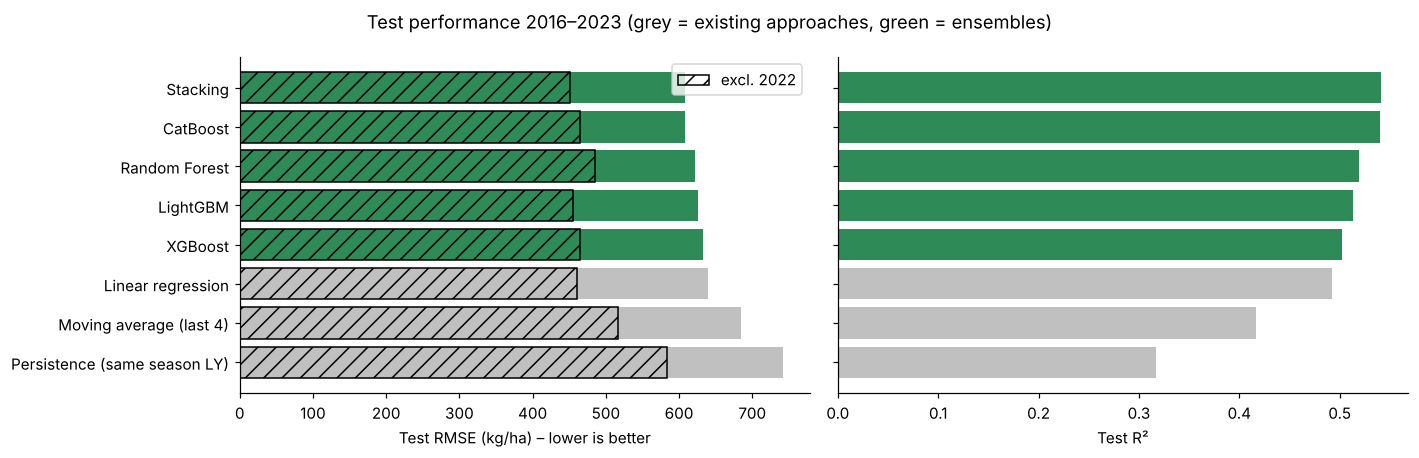

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
r = res.sort_values("RMSE")
cols = ["#c0c0c0" if n in ["Persistence (same season LY)", "Moving average (last 4)", "Linear regression"] else "#2e8b57" for n in r.index]
axes[0].barh(r.index, r["RMSE"], color=cols); axes[0].invert_yaxis()
axes[0].barh(r.index, r["RMSE excl. 2022"], color="none", edgecolor="black", hatch="//", label="excl. 2022")
axes[0].set_xlabel("Test RMSE (kg/ha) – lower is better"); axes[0].legend()
axes[1].barh(r.index, r["R2"], color=cols); axes[1].invert_yaxis(); axes[1].set_xlabel("Test R²")
axes[1].set_yticklabels([])
fig.suptitle("Test performance 2016–2023 (grey = existing approaches, green = ensembles)")
savefig("05_model_comparison")

In [20]:
BEST = res.index[0]
print("Selected model (lowest CV RMSE):", BEST)
best_model = fitted[BEST]
test_pred = best_model.predict(X_test)
by_year = test.assign(pred=test_pred, err=test_pred - y_test).groupby(["Year", "Season"]).agg(
    actual=(TARGET, "mean"), predicted=("pred", "mean"), MAE=("err", lambda e: e.abs().mean())).round(0)
by_year

Selected model (lowest CV RMSE): LightGBM


actual  predicted     MAE
Year Season                           
2016 MAHA    4011.0     4081.0   214.0
     YALA    3946.0     4070.0   307.0
2017 MAHA    3983.0     3985.0   325.0
     YALA    3780.0     4014.0   394.0
2018 MAHA    4000.0     3982.0   277.0
     YALA    4232.0     4003.0   327.0
2019 MAHA    4567.0     4026.0   597.0
     YALA    4366.0     4192.0   471.0
2020 MAHA    4531.0     4271.0   365.0
     YALA    4552.0     4241.0   350.0
2021 MAHA    4307.0     4314.0   376.0
     YALA    4309.0     4287.0   331.0
2022 MAHA    2853.0     4266.0  1413.0
     YALA    3207.0     4114.0   907.0
2023 MAHA    3554.0     3648.0   277.0
     YALA    3774.0     3628.0   268.0

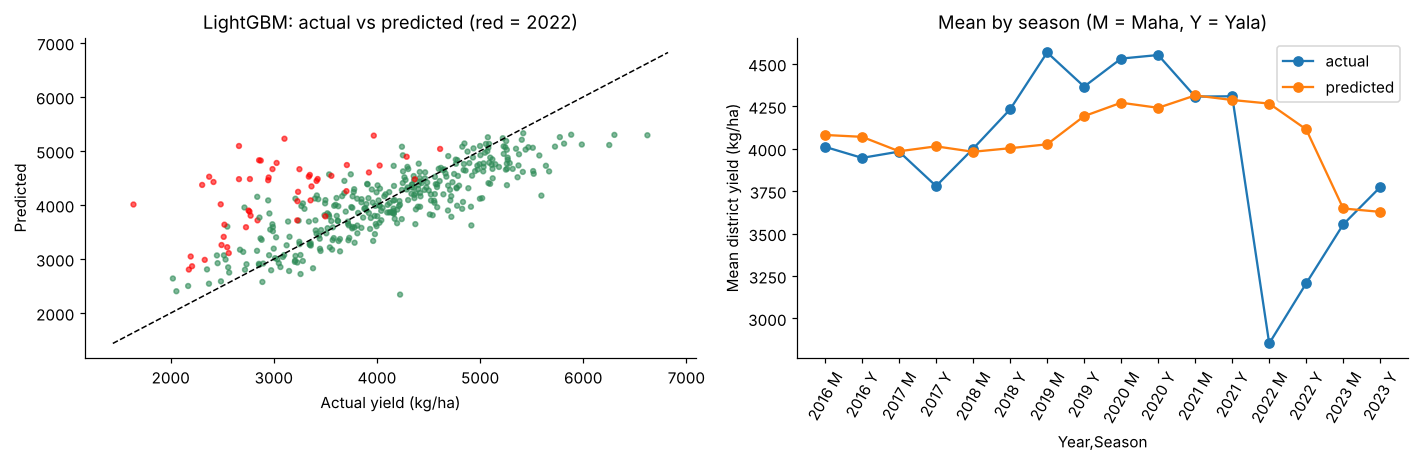

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].scatter(y_test, test_pred, s=10, alpha=0.6, c=(test["Year"] == 2022).map({True: "red", False: "#2e8b57"}))
lims = [y_test.min() - 200, y_test.max() + 200]; axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("Actual yield (kg/ha)"); axes[0].set_ylabel("Predicted"); axes[0].set_title(f"{BEST}: actual vs predicted (red = 2022)")
by_year[["actual", "predicted"]].plot(ax=axes[1], marker="o")
axes[1].set_xticks(range(len(by_year))); axes[1].set_xticklabels([f"{y} {s[0]}" for y, s in by_year.index], rotation=60)
axes[1].set_ylabel("Mean district yield (kg/ha)"); axes[1].set_title("Mean by season (M = Maha, Y = Yala)")
savefig("06_best_model_fit")

### Interpreting the comparison
* **Every ensemble beats the existing approaches in cross-validation**: CV RMSE ≈ 425–437 kg/ha vs 442 (moving average), 477 (persistence) and 513 (linear regression) – about **17 % lower error than linear regression**.
* **On the 2016–2023 test period** the selected LightGBM reduces RMSE by **≈16 % vs persistence** (626 vs 742 kg/ha) and **≈9 % vs the moving average**; excluding the 2022 shock the gain vs persistence is **≈22 %** (455 vs 583 kg/ha). About 60 % of district-season forecasts are within ±10 % of the actual yield.
* The advantage over **linear regression shrinks on the test period** (626 vs 639). Reason: 2019–2021 brought *record* yields, outside the 1979–2015 training range. Tree ensembles predict averages of training leaves and **cannot extrapolate a trend**, whereas a linear `Year` term can. This is a real limitation and is why the final model is **retrained on data up to 2023** before deployment, and why monitoring/retraining (MLOps) matters.
* **Stacking** gives the best raw test RMSE (608) by mixing RF + CatBoost errors, but its CV score is slightly worse than LightGBM and it is ~4× more complex to deploy and explain. Following the rule "select on validation, report on test", **LightGBM** is chosen; Stacking is a close alternative.
* **2022 (fertilizer ban)**: LightGBM's errors are 2.5–4 times larger than in normal seasons (MAE ≈ 1,400 kg/ha in Maha and ≈ 900 in Yala vs ≈ 350 otherwise, see the table above), and every model, including the baselines, over-predicts that year. Shocks are not predictable from history alone.

### Strengths and limitations of each model (interpreted from the results above)
| Model | Strengths | Limitations |
|---|---|---|
| Persistence / moving average | No training, transparent, already "good" because yields are persistent | Cannot react to sown area, irrigation mix or trend; lags one season behind every change |
| Linear regression | Fast, coefficients readable, captures trend | Assumes additive linear effects; unstable with collinear shares/lags; no interactions (e.g. Yala × rain-fed) |
| Random Forest | Robust, little tuning sensitivity, handles collinearity and missing-pattern noise | Cannot extrapolate beyond the training range (tree leaves are averages) – a problem for an upward-trending target; larger model file |
| XGBoost | Strong accuracy, regularisation (L1/L2, subsampling), fast with `hist` | Many interacting hyperparameters; needs one-hot for districts; can over-fit small data without careful tuning |
| LightGBM | Fastest training, leaf-wise trees capture interactions | Leaf-wise growth over-fits easily on < 2k rows – needed small `num_leaves` and large `min_child_samples` |
| CatBoost | Native categorical handling (no one-hot), ordered boosting reduces target leakage, good defaults-region | Slowest to train; less transparent encoding of districts |
| Stacking | Combines bagging + boosting errors; usually the most stable | Most complex to deploy and explain; gain over the best single model is small; meta-learner needs careful CV |

**Common limitation:** none of the models can foresee a policy shock such as the 2021 fertilizer ban – the information is simply not in the features. Errors in 2022 are therefore much larger for *every* model, including the baselines.

## 9. Explainability (post-hoc, as covered in the lectures)
* **SHAP** (Shapley additive explanations, from cooperative game theory) – *global* view: which features drive yield predictions across all districts and seasons, and in which direction; plus a *local* waterfall for a single prediction.
* **LIME** (Local Interpretable Model-agnostic Explanations) – fits a simple weighted linear surrogate model around one instance to explain that single prediction.

TreeSHAP needs a single tree model, so SHAP is computed on the best **tree-based** model; LIME is model-agnostic and explains the final selected model directly.

SHAP explained model: LightGBM


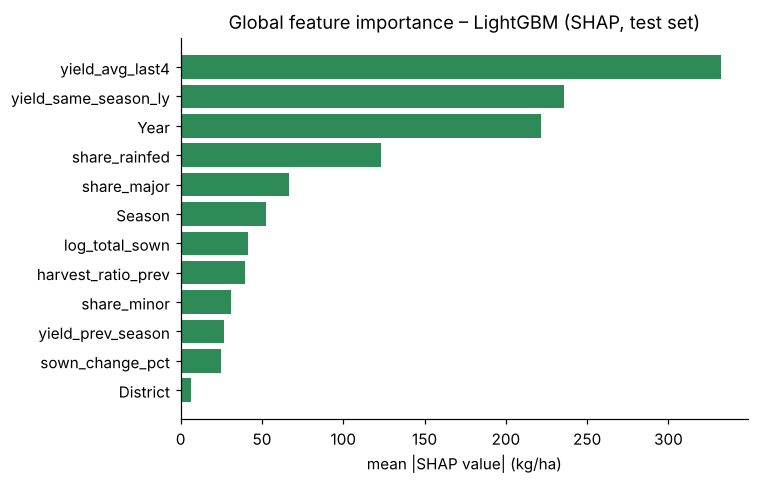

In [22]:
tree_models = [m for m in res.index if m in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]]
EXPLAIN = tree_models[0]
exp_pipe = fitted[EXPLAIN]
prep, est = exp_pipe.named_steps["prep"], exp_pipe.named_steps["model"]
Xt_test = prep.transform(X_test)
feat_names = list(prep.get_feature_names_out())
Xt_test = pd.DataFrame(np.asarray(Xt_test), columns=feat_names)
if EXPLAIN == "CatBoost":
    Xt_test[NUM_FEATURES] = Xt_test[NUM_FEATURES].astype(float)
explainer = shap.TreeExplainer(est.model_ if EXPLAIN == "CatBoost" else est)
sv = explainer(Xt_test)
print("SHAP explained model:", EXPLAIN)

# group one-hot columns back to their original feature so 'District' is one feature
def group_shap(values, names):
    df = pd.DataFrame(values, columns=names)
    groups = {n: ("District" if n.startswith("District_") else "Season" if n.startswith("Season_") else n) for n in names}
    return df.T.groupby(pd.Series(groups)).sum().T

shap_grouped = group_shap(sv.values, feat_names)
imp = shap_grouped.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color="#2e8b57"); ax.set_xlabel("mean |SHAP value| (kg/ha)")
ax.set_title(f"Global feature importance – {EXPLAIN} (SHAP, test set)")
savefig("07_shap_importance")

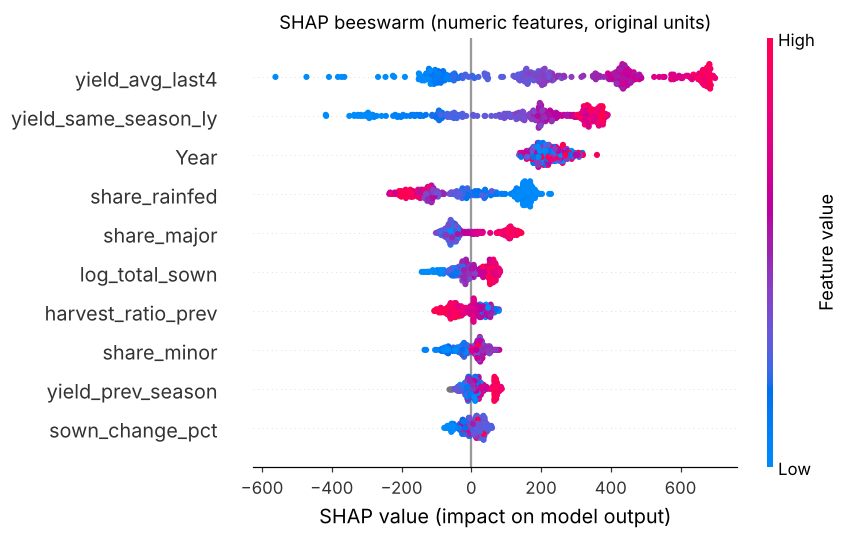

In [23]:
num_idx = [feat_names.index(f) for f in NUM_FEATURES]
raw_test_num = X_test[NUM_FEATURES].reset_index(drop=True)
plt.figure()
shap.summary_plot(sv.values[:, num_idx], raw_test_num, feature_names=NUM_FEATURES, show=False, plot_size=(8, 5))
plt.title("SHAP beeswarm (numeric features, original units)")
savefig("08_shap_beeswarm")

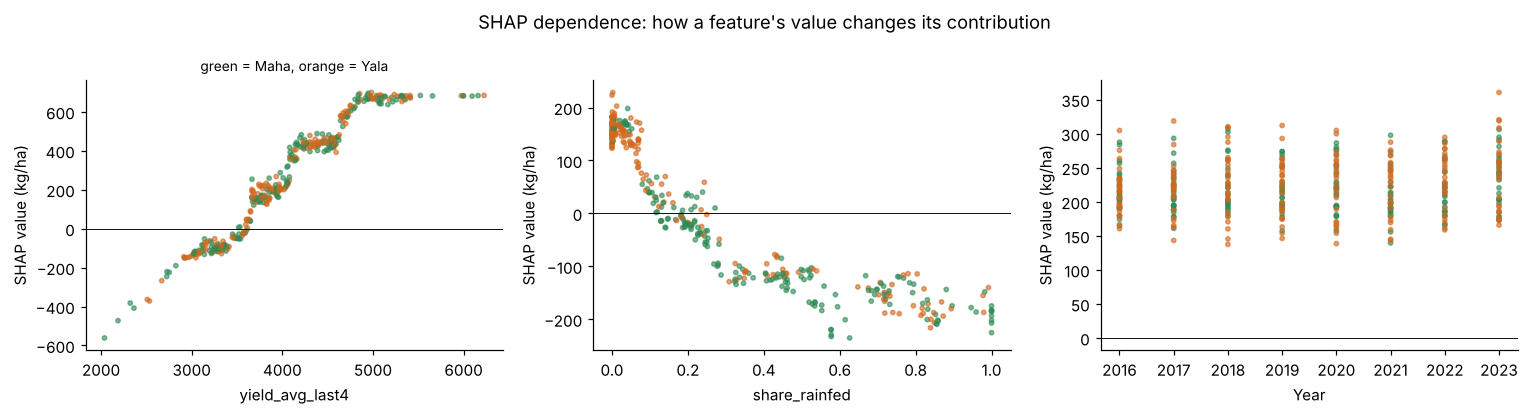

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, f in zip(axes, ["yield_avg_last4", "share_rainfed", "Year"]):
    ax.scatter(raw_test_num[f], sv.values[:, feat_names.index(f)], s=8, alpha=0.6,
               c=(X_test["Season"] == "YALA").map({True: "#d2691e", False: "#2e8b57"}).values)
    ax.axhline(0, color="k", lw=0.6); ax.set_xlabel(f); ax.set_ylabel("SHAP value (kg/ha)")
axes[0].set_title("green = Maha, orange = Yala", fontsize=9)
fig.suptitle("SHAP dependence: how a feature's value changes its contribution")
savefig("09_shap_dependence")

**Interpreting the SHAP results**
* The district's **recent yield history** (`yield_avg_last4`, `yield_same_season_ly`) is the strongest driver: a district that averaged high yields in the last four seasons is predicted high again. The relationship is close to linear — yields are persistent.
* **`District` itself adds very little** once history and irrigation mix are known: the location effect seen in the EDA box-plot is already *encoded* in each district's past yields and its irrigation shares. This is a useful finding – the model generalises through agronomic drivers rather than memorising district names.
* **`share_rainfed`** has a negative effect: the more of the sown area depends on rain alone, the lower the expected yield — consistent with agronomy (no water control, more drought/flood risk). This is stronger in **Yala**, which receives less rain in the dry zone.
* **`Year`** captures the long-term technology trend (better varieties and inputs), pushing recent seasons up.
* Sown area change and last season's harvest ratio have smaller, mostly non-linear effects (they matter mainly in abnormal seasons).

The model's reasoning therefore matches domain knowledge – an important trust check (no leakage or spurious feature dominating).

### 9.2 Local explanation of one prediction: the held-out sample (Polonnaruwa, Yala 2023)
For deployment the selected model is **retrained on all available seasons (1979–2023, except the held-out sample)** with the tuned hyperparameters, so it has seen the most recent yield levels. The local explanations below explain *this final model*, i.e. exactly the prediction the app will give.

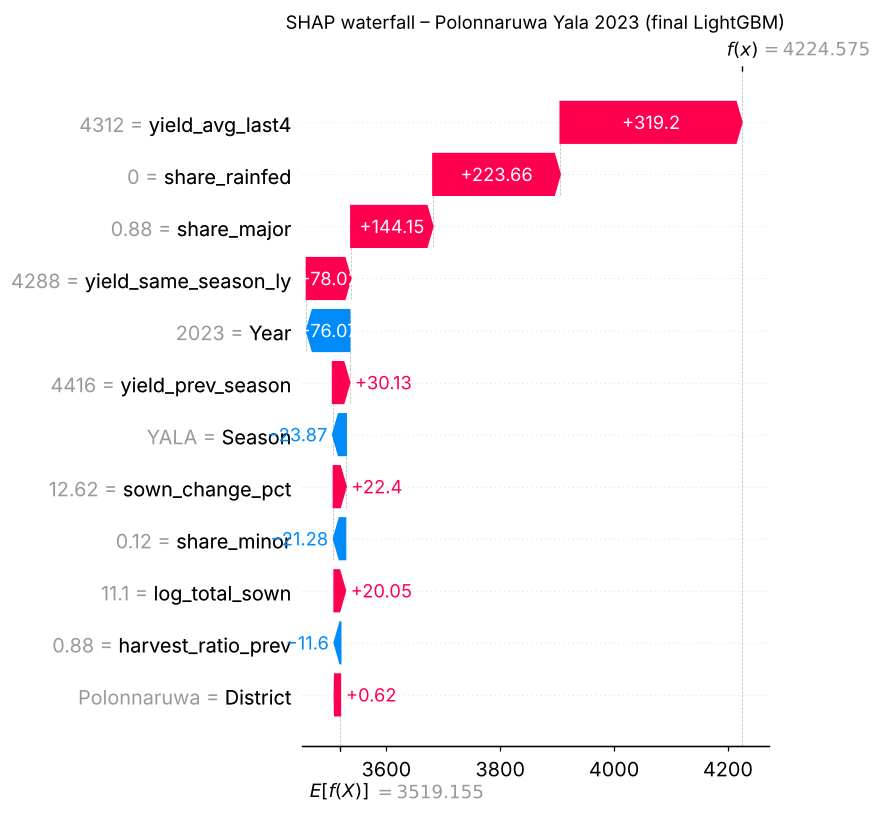

In [25]:
from sklearn.base import clone
final_model = clone(best_model)
final_model.fit(data[FEATURES], data[TARGET])
if BEST == EXPLAIN:
    prep, est = final_model.named_steps["prep"], final_model.named_steps["model"]
    explainer = shap.TreeExplainer(est.model_ if EXPLAIN == "CatBoost" else est)
x_hold = holdout[FEATURES]
xh = pd.DataFrame(np.asarray(prep.transform(x_hold)), columns=feat_names)
if EXPLAIN == "CatBoost":
    xh[NUM_FEATURES] = xh[NUM_FEATURES].astype(float)
sv_h = explainer(xh)
g = group_shap(sv_h.values, feat_names).iloc[0]
disp = {f: (holdout[f].iloc[0] if f in holdout else "") for f in g.index}
expl = shap.Explanation(values=g.values, base_values=float(np.ravel(sv_h.base_values)[0]),
                        data=np.array([disp[f] if isinstance(disp[f], str) else round(float(disp[f]), 2) for f in g.index], dtype=object),
                        feature_names=list(g.index))
plt.figure(figsize=(9, 6))
shap.plots.waterfall(expl, max_display=12, show=False)
plt.title(f"SHAP waterfall – Polonnaruwa Yala 2023 (final {EXPLAIN})")
savefig("10_shap_waterfall")

**Reading the waterfall.** Starting from the average prediction (≈3,520 kg/ha), Polonnaruwa's high recent yields (+≈320), zero rain-fed area (+≈220) and 88 % major irrigation (+≈145) push the forecast up to ≈4,225 kg/ha.
Notice that **`Year = 2023` pulls the forecast *down***: after retraining on 2022, the model has learned that the most recent years were low (fertilizer ban). In reality yields recovered in 2023 (actual 4,918 kg/ha), so this is precisely why the forecast is ~14 % too low. SHAP turns an unexplained error into a diagnosable one – exactly the "debugging" and "trust calibration" uses of XAI discussed in the lecture.
In the dependence plot above, `Year`'s SHAP value is also flat across 2016–2023: trees cannot extend the upward trend beyond the training data.

### 9.3 LIME explanation of the same sample (final selected model)

LIME local surrogate R² = 0.63 | surrogate prediction = 4425 kg/ha


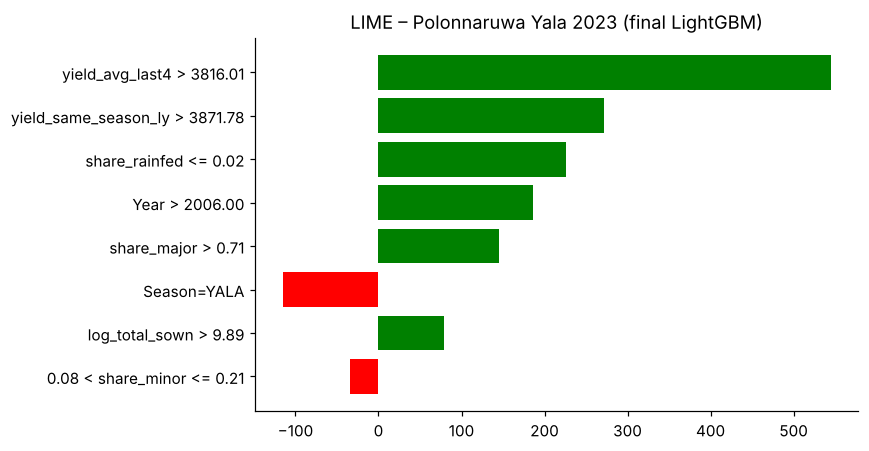

,condition,effect (kg/ha)
0,yield_avg_last4 > 3816.01,544.6
1,yield_same_season_ly > 3871.78,271.8
2,share_rainfed <= 0.02,225.4
3,Year > 2006.00,186.2
4,share_major > 0.71,145.6
5,Season=YALA,-115.5
6,log_total_sown > 9.89,78.9
7,0.08 < share_minor <= 0.21,-34.5


In [26]:
cat_maps = {c: sorted(train[c].unique()) for c in CAT_FEATURES}
def encode(df):
    out = df[FEATURES].copy()
    for c in CAT_FEATURES:
        out[c] = out[c].map({v: i for i, v in enumerate(cat_maps[c])})
    return out.astype(float)
def predict_from_encoded(arr):
    df = pd.DataFrame(arr, columns=FEATURES)
    for c in CAT_FEATURES:
        df[c] = df[c].round().astype(int).clip(0, len(cat_maps[c]) - 1).map(dict(enumerate(cat_maps[c])))
    return final_model.predict(df[FEATURES])

enc_train = encode(train)
lime_exp = LimeTabularExplainer(
    enc_train.fillna(enc_train.median()).values, feature_names=FEATURES, mode="regression",
    categorical_features=[FEATURES.index(c) for c in CAT_FEATURES],
    categorical_names={FEATURES.index(c): cat_maps[c] for c in CAT_FEATURES},
    discretize_continuous=True, random_state=RANDOM_STATE)
x_enc = encode(holdout).fillna(enc_train.median()).values[0]
le = lime_exp.explain_instance(x_enc, predict_from_encoded, num_features=8, num_samples=3000)
print(f"LIME local surrogate R² = {le.score:.2f} | surrogate prediction = {le.local_pred[0]:.0f} kg/ha")
fig = le.as_pyplot_figure(); fig.set_size_inches(8, 4.2)
plt.title(f"LIME – Polonnaruwa Yala 2023 (final {BEST})")
savefig("11_lime")
pd.DataFrame(le.as_list(), columns=["condition", "effect (kg/ha)"]).round(1)

**SHAP vs LIME on the same case.** Both agree on the main story for Polonnaruwa: a high recent yield history, no rain-fed area and a large major-irrigation share push the forecast well above average, while the Yala season pulls it slightly down.
They **disagree on `Year`**: LIME says "Year > 2006" helps, SHAP says 2023 hurts. LIME discretises features into coarse bins and fits a local linear surrogate on perturbed samples (local R² ≈ 0.63 here, so it is only an approximation and can vary between runs), so it compares "recent vs old years". SHAP values are exact additive contributions for tree models and capture the specific 2022–23 dip. Using both is a useful cross-check, and their disagreement is itself informative.

## 10. Save the model and run inference on the unseen sample
The final (retrained) model is saved with `pickle` together with the metadata the front-end needs.

In [27]:
history = feat_all[["District", "Season", "Year", "t", "Major Sown (Ha)", "Minor Sown (Ha)", "Rainfed Sown (Ha)",
                    "Total Extent (Ha)", "Net Harvest (Ha)", TARGET]]
bundle = {
    "model": final_model, "model_name": BEST, "features": FEATURES,
    "districts": sorted(model_df["District"].unique()), "seasons": ["MAHA", "YALA"],
    "test_rmse": float(res.loc[BEST, "RMSE"]), "test_mae": float(res.loc[BEST, "MAE"]),
    "trained_on": "1979-2023 (excluding Polonnaruwa Yala 2023 hold-out)",
}
with open(MODELS / "paddy_yield_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
history.to_csv(MODELS / "district_history.csv", index=False)
res.round(3).to_csv(MODELS / "model_comparison.csv")
json.dump({k: {kk: (vv if not isinstance(vv, (np.integer, np.floating)) else vv.item()) for kk, vv in v.items()}
           for k, v in best_params.items()}, open(MODELS / "best_hyperparameters.json", "w"), indent=2)
print("Saved:", MODELS / "paddy_yield_model.pkl", f"({(MODELS / 'paddy_yield_model.pkl').stat().st_size/1e6:.1f} MB)")

Saved: /home/claude/proj/models/paddy_yield_model.pkl (1.2 MB)


In [28]:
# --- Inference: load the pickle as a separate application would, and predict the unseen sample ---
with open(MODELS / "paddy_yield_model.pkl", "rb") as f:
    loaded = pickle.load(f)
row = holdout.iloc[0]
pred = loaded["model"].predict(holdout[loaded["features"]])[0]
print(f"Input: {row['District']} | {row['Season']} {row['Year']} | sown {row['Total Extent (Ha)']:,.0f} ha "
      f"(major {row['share_major']:.0%}, minor {row['share_minor']:.0%}, rain-fed {row['share_rainfed']:.0%})")
print(f"History: last season {row['yield_prev_season']:,.0f} | same season last year {row['yield_same_season_ly']:,.0f} | avg last 4 {row['yield_avg_last4']:,.0f} kg/ha")
print(f"Predicted yield : {pred:,.0f} kg/ha")
print(f"Actual yield    : {row[TARGET]:,.0f} kg/ha   (error {pred-row[TARGET]:+,.0f} kg/ha, {100*(pred-row[TARGET])/row[TARGET]:+.1f} %)")
print(f"Implied production if the sown area is harvested at last season's ratio: "
      f"{pred/1000 * row['Total Extent (Ha)'] * row['harvest_ratio_prev']:,.0f} t  (actual {row['Production (MT)']:,.0f} t)")

Input: Polonnaruwa | YALA 2023 | sown 66,033 ha (major 88%, minor 12%, rain-fed 0%)
History: last season 4,416 | same season last year 4,288 | avg last 4 4,312 kg/ha
Predicted yield : 4,225 kg/ha
Actual yield    : 4,918 kg/ha   (error -693 kg/ha, -14.1 %)
Implied production if the sown area is harvested at last season's ratio: 246,632 t  (actual 287,105 t)


## 11. Conclusions
* **Problem:** forecasting district paddy yield at sowing time for Sri Lanka's Maha and Yala seasons, using DCS statistics (1979–2023).
* **Data work mattered:** removing 100 duplicate rows and 4 overlapping aggregate regions, fixing the kg/ha unit error, and building leakage-free lag features were essential before any modelling.
* **Results:** all tuned ensembles beat the existing approaches in time-series cross-validation (LightGBM CV RMSE 425 vs 513 kg/ha for linear regression and 477 for persistence). On unseen 2016–2023 seasons LightGBM's RMSE is 626 kg/ha (MAPE ≈ 13 %), 16 % better than persistence, 22 % better outside the 2022 shock year.
* **Honest caveat:** on the test period linear regression is close behind, because tree models cannot extrapolate the record yields of 2019–2021; retraining on recent data (done for the saved model) and drift monitoring address this.
* **Explainability:** SHAP and LIME show the model relies on yield history, district, irrigation mix (rain-fed share ↓) and the long-term trend – consistent with Sri Lankan agronomy, which builds trust in the predictions.
* **Limitation:** policy or climate shocks (2022 fertilizer ban) are not predictable from these features; every model over-predicts 2022, with errors 2.5–4 times larger than in normal seasons.

**Future work:** add Department of Meteorology rainfall and reservoir (tank) storage at sowing time, fertilizer issue data, and monitor the deployed model for data drift (as in the MLOps workshop) so shocks like 2022 trigger alerts and retraining.